# Dengue Outbreak Early-Warning for Sri Lanka's 26 RDHS Divisions
### Applied Machine Learning — Class Activity (RF vs XGBoost) extended into the Final Assignment

**Problem (local, Sri Lankan context).** Dengue is Sri Lanka's most burdensome vector-borne disease (174,687 reported cases in the 2017 epidemic alone in this dataset). Every week the **Epidemiology Unit of the Ministry of Health** publishes the *Weekly Epidemiological Report (WER)* with dengue notifications for each of the 26 **RDHS** (Regional Director of Health Services) divisions. Regional health officers must decide **where to send fogging teams, Public Health Inspectors and extra hospital capacity next week**.

**ML task — binary classification.** *Given the dengue situation in a district at the end of week t, will week t+1 be a "high-transmission week" for that district?*

- **Target** `outbreak_next_week = 1` if next week's cases ≥ the district's own 75th-percentile weekly count over 2007–2021 (a district-specific alert threshold, so Colombo and Mullaitivu are each judged against their own normal).
- **Why classification and not raw-count regression?** The operational decision is binary (escalate vector control or not) and the count distribution is extremely skewed (0 to 2,631/week).

**Notebook map**
1. Data collection & quality checks → 2. EDA → 3. Target & feature engineering (domain knowledge) → 4. Temporal split & single held-out sample → 5. Preprocessing → 6. Existing-approach baselines → 7. **Part 1: Random Forest vs XGBoost with designed + tuned hyper-parameters** → 8. Soft voting (lecture notebook), LightGBM, CatBoost, **Stacking** → 9. Model selection & final test → 10. **Explainability: SHAP + LIME** → 11. **Single-sample inference from the .pkl** + next-week forecast → 12. Export → 13. Conclusions.

In [1]:
import sys, time, pickle, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from features import (load_raw, clean_implausible_dips, district_thresholds, build_panel_features, features_from_inputs,
                      DISTRICT_META, CAT_FEATURES, NUM_FEATURES, FEATURES, TARGET)
from cb_wrapper import CatBoostWrapper

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, KFold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap, lime, lime.lime_tabular

SEED = 42
import os; FAST = os.environ.get("FAST") == "1"   # quick smoke-test mode (CI); full run uses FAST=False
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("xgboost", __import__("xgboost").__version__, "| lightgbm", __import__("lightgbm").__version__,
      "| catboost", __import__("catboost").__version__, "| shap", shap.__version__)

xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10 | shap 0.54.1


## 1. Data collection

**Source:** Epidemiology Unit, Ministry of Health Sri Lanka — Weekly Epidemiological Reports (WER), district-level dengue notifications, Dec 2006 → May 2026. The PDFs were scraped and tidied by the open-source R package **`denguedatahub`** (Talagala, University of Sri Jayewardenepura; GitHub `thiyangt/denguedatahub`, object `srilanka_weekly_data`). I exported it to `data/raw/srilanka_weekly_dengue.csv`.

| column | meaning |
|---|---|
| `year`, `week` | epidemiological year and week number |
| `start.date`, `end.date` | the reporting week |
| `district` | RDHS division (25 districts + **Kalmune**, a separate RDHS carved out of Ampara) |
| `cases` | dengue notifications that week |

In [2]:
raw = pd.read_csv(ROOT / "data/raw/srilanka_weekly_dengue.csv")
print(raw.shape); display(raw.head())
df = load_raw(ROOT / "data/raw/srilanka_weekly_dengue.csv")
print("Period:", df.date.min().date(), "→", df.date.max().date(), "| districts:", df.district.nunique())

(26311, 6)


,year,week,start.date,end.date,district,cases
0,"2,006.000",52.000,12/23/2006,12/29/2006,Colombo,71.000
1,"2,006.000",52.000,12/23/2006,12/29/2006,Gampaha,12.000
2,"2,006.000",52.000,12/23/2006,12/29/2006,Kalutara,12.000
3,"2,006.000",52.000,12/23/2006,12/29/2006,Kandy,20.000
4,"2,006.000",52.000,12/23/2006,12/29/2006,Matale,4.000


Period: 2006-12-23 → 2026-05-11 | districts: 26


### 1.1 Data-quality checks (nulls, duplicates, impossible values, gaps)

In [3]:
checks = {
    "null values (any column)": int(raw.isna().sum().sum()),
    "duplicate district-week rows": int(df.duplicated(["district", "date"]).sum()),
    "negative case counts": int((df.cases < 0).sum()),
    "non-integer case counts": int((df.cases % 1 != 0).sum()),
}
gaps = df.groupby("district")["date"].diff().dt.days.value_counts().rename("count")
rows_per_district = df.district.value_counts()
display(pd.Series(checks, name="result").to_frame())
print("Days between consecutive reports (per district):"); display(gaps.to_frame())
print("District with a missing week:", rows_per_district[rows_per_district < rows_per_district.max()].to_dict())

,result
null values (any column),0
duplicate district-week rows,0
negative case counts,0
non-integer case counts,0


Days between consecutive reports (per district):


,count
date,
7.000,26206
8.000,26
6.000,26
9.000,26
14.000,1


District with a missing week: {'Puttalam': 1011}


In [4]:
# Locate Puttalam's missing week and the irregular 6/8/9-day reporting intervals
all_dates = pd.Index(sorted(df.date.unique()))
missing = all_dates.difference(df[df.district == "Puttalam"].date)
print("Puttalam missing report week:", [d.date() for d in missing])
odd = df.assign(gap=df.groupby("district").date.diff().dt.days).query("gap not in [7] and gap == gap")
display(odd.drop_duplicates("date")[["date", "year", "week", "gap"]])

Puttalam missing report week: [datetime.date(2026, 2, 9)]


,date,year,week,gap
122,2009-04-26,2009,18,8.000
127,2009-05-30,2009,23,6.000
992,2025-12-29,2026,1,9.000
23262,2026-02-16,2026,8,14.000


### 1.2 Outlier detection: implausible one-week collapses
A scan of the series shows isolated weeks where a large district suddenly reports almost nothing and then bounces straight back (e.g. Colombo **316 → 9 → 291** in March 2026). Dengue transmission cannot stop for exactly one week and resume, and the values (9, 10, 11, 12…) look like a **dropped digit** when the WER PDFs were transcribed. Rule: *both neighbouring weeks ≥ 50 cases and the week < 15 % of the smaller neighbour* → treat as an error and impute with the geometric mean of the neighbours (log-space interpolation). Genuine epidemic peaks (high outliers) are **not** touched.

In [5]:
df, flagged = clean_implausible_dips(df)
print(f"Flagged and imputed {len(flagged)} of {len(df):,} district-weeks ({len(flagged)/len(df):.2%})")
display(flagged)

Flagged and imputed 22 of 26,311 district-weeks (0.08%)


,district,date,cases,prev_week,next_week,imputed
0,Badulla,2023-12-16,16.000,178.000,120.000,146.000
1,Colombo,2012-06-09,0.000,70.000,72.000,71.000
2,Colombo,2012-07-14,0.000,99.000,206.000,143.000
3,Colombo,2016-03-26,20.000,174.000,136.000,154.000
4,Colombo,2021-10-16,19.000,132.000,190.000,158.000
5,Colombo,2022-11-19,10.000,71.000,79.000,75.000
6,Colombo,2026-03-30,9.000,316.000,291.000,303.000
7,Galle,2016-12-10,7.000,91.000,79.000,85.000
8,Galle,2023-11-04,4.000,83.000,83.000,83.000
9,Gampaha,2021-10-16,12.000,93.000,104.000,98.000


**Findings.** No nulls, duplicates or negative values in the raw table, but 22 transcription-type low outliers were found and imputed (1.2). Puttalam is missing one week (Feb 2026, an un-reported week in the WER — it only shifts that district's lags by one week for a few rows) and three report dates shift by ±1–2 days at year boundaries (WER week-numbering changes) — both harmless for weekly lags. **Missing values do appear after feature engineering** (lags at the start of each series, and *same week last year* during 2007), which is handled with median imputation + missing-indicator flags inside the model pipeline (Section 5). Extreme values (e.g. Colombo's 2,631 cases in a single 2017 week) are **real epidemic weeks, not errors**, so they are kept and tamed with a `log1p` transform instead of being clipped.

## 2. Exploratory data analysis

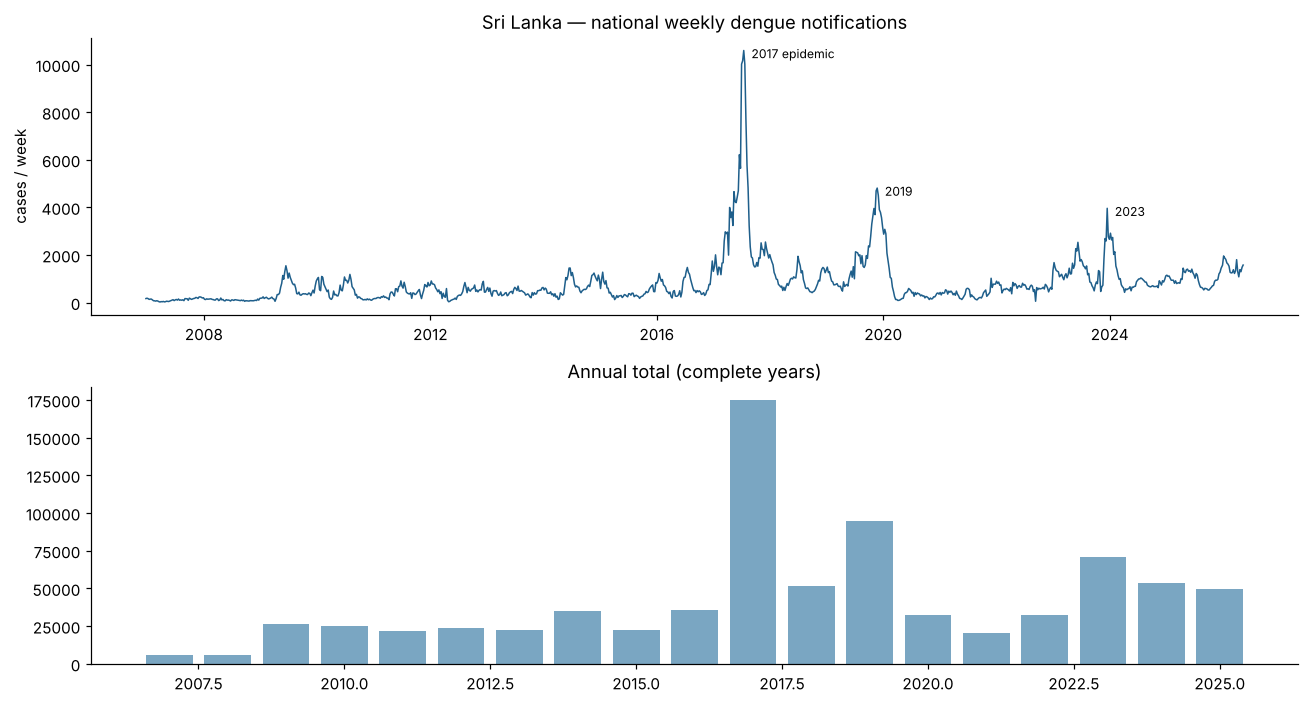

In [6]:
nat = df.groupby("date").cases.sum()
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5))
ax[0].plot(nat.index, nat.values, lw=1, color="#1f5f8b")
ax[0].set_title("Sri Lanka — national weekly dengue notifications"); ax[0].set_ylabel("cases / week")
for yr, lbl in [(2017, "2017 epidemic"), (2019, "2019"), (2023, "2023")]:
    s = nat[str(yr)]; ax[0].annotate(lbl, (s.idxmax(), s.max()), xytext=(5, -5), textcoords="offset points", fontsize=8)
yearly = df[df.year.between(2007, 2025)].groupby("year").cases.sum()
ax[1].bar(yearly.index, yearly.values, color="#7aa6c2"); ax[1].set_title("Annual total (complete years)")
plt.tight_layout(); plt.savefig(FIG / "01_national_trend.png", bbox_inches="tight"); plt.show()

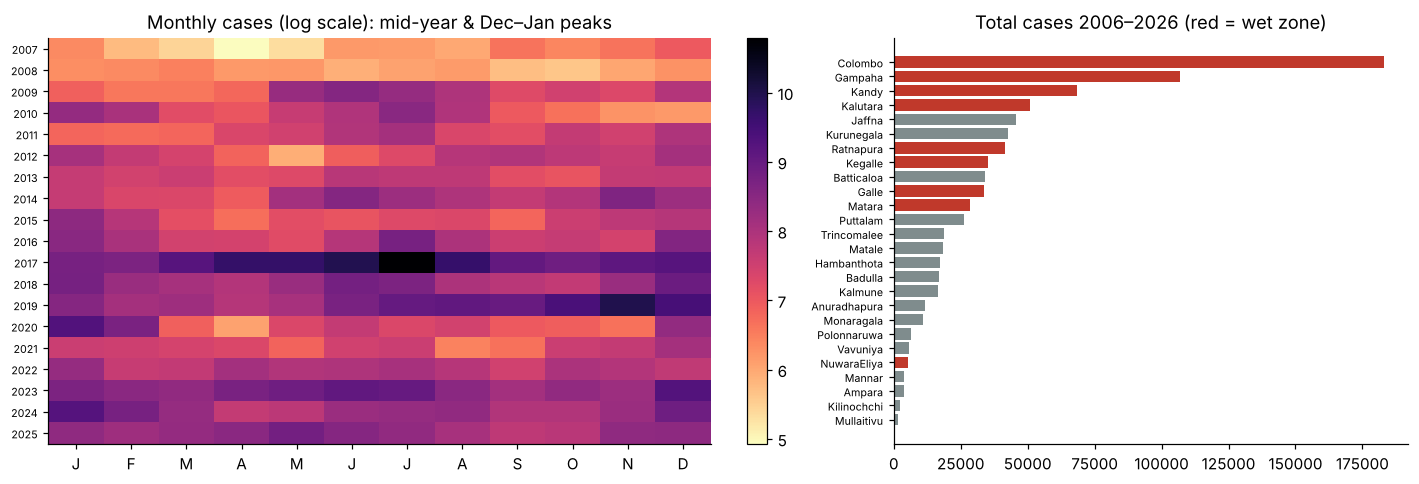

Share of all cases in Western Province: 0.408


In [7]:
df["month"] = df.date.dt.month
season = df.groupby(["year", "month"]).cases.sum().unstack().loc[2007:2025]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
im = ax[0].imshow(np.log1p(season.values), aspect="auto", cmap="magma_r")
ax[0].set_yticks(range(len(season)), season.index, fontsize=7); ax[0].set_xticks(range(12), list("JFMAMJJASOND"))
ax[0].set_title("Monthly cases (log scale): mid-year & Dec–Jan peaks"); plt.colorbar(im, ax=ax[0], fraction=0.03)
dist_tot = df.groupby("district").cases.sum().sort_values()
ax[1].barh(dist_tot.index, dist_tot.values, color=["#c0392b" if DISTRICT_META[d][1] == "Wet" else "#7f8c8d" for d in dist_tot.index])
ax[1].set_title("Total cases 2006–2026 (red = wet zone)"); ax[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig(FIG / "02_seasonality_districts.png", bbox_inches="tight"); plt.show()
print("Share of all cases in Western Province:", round(df[df.district.isin(['Colombo','Gampaha','Kalutara'])].cases.sum() / df.cases.sum(), 3))

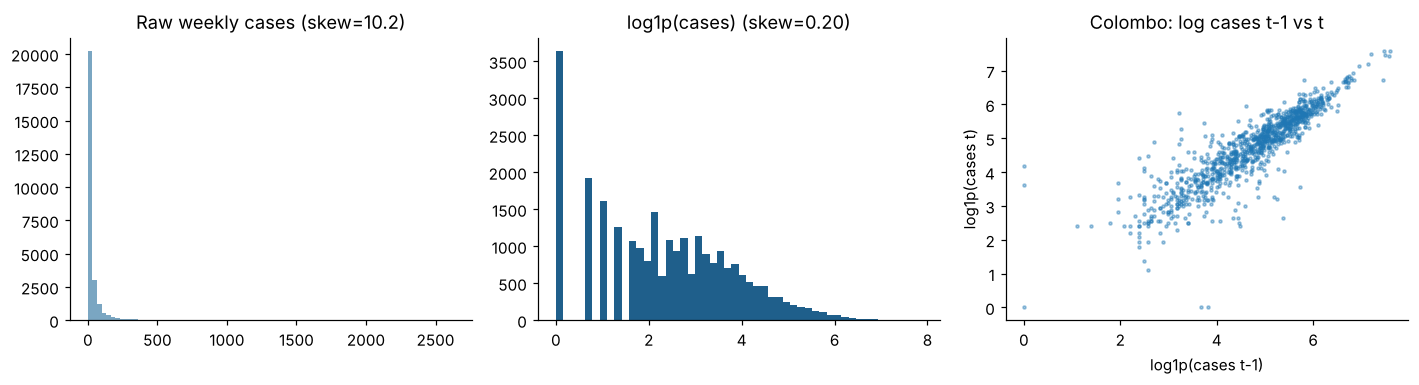

,1,2,4,8,26,52
autocorr,0.878,0.818,0.740,0.585,0.503,0.330


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(df.cases, bins=80, color="#7aa6c2"); ax[0].set_title(f"Raw weekly cases (skew={df.cases.skew():.1f})")
ax[1].hist(np.log1p(df.cases), bins=50, color="#1f5f8b"); ax[1].set_title(f"log1p(cases) (skew={np.log1p(df.cases).skew():.2f})")
c = df[df.district == "Colombo"].set_index("date").cases
ax[2].scatter(np.log1p(c.shift(1)), np.log1p(c), s=4, alpha=.4); ax[2].set_title("Colombo: log cases t-1 vs t")
ax[2].set_xlabel("log1p(cases t-1)"); ax[2].set_ylabel("log1p(cases t)")
plt.tight_layout(); plt.savefig(FIG / "03_distribution_autocorr.png", bbox_inches="tight"); plt.show()
ac = pd.Series({k: np.log1p(c).autocorr(k) for k in [1, 2, 4, 8, 26, 52]}, name="autocorr")
display(ac.to_frame().T)

**EDA take-aways that drive the design**
- **Strong persistence**: log-cases autocorrelation ≈ 0.83 at lag 1 (still 0.70 at lag 4) → recent lags will be the backbone features (a naive "this week is high → next week is high" rule is the baseline to beat).
- **Bi-modal seasonality** linked to the **South-West monsoon (May–Jul)** and **North-East monsoon (Dec–Jan)** → cyclical week encoding + a `monsoon_season` category.
- **Wet-zone / urban districts dominate** (Western Province ≈ 40 % of all cases) → district, province and agro-climatic zone features; thresholds must be *district-specific*.
- **Heavy right skew** (see histogram titles) → `log1p` transformation; tree ensembles are scale-invariant, but the log helps the linear baseline and the growth-rate features.
- **Regime changes**: 2017 epidemic, COVID-19 lockdowns (2020–21: low reporting), high years 2023–24 → a **temporal** validation is mandatory (random K-fold would leak the future).

## 3. Target definition & feature engineering

All features at row *t* use only data available at the end of week *t* (no look-ahead). The per-district threshold is computed **only from 2007–2021 (training period)** to avoid target leakage.

| group | features | rationale (domain knowledge) |
|---|---|---|
| Recent burden | `log_c0..log_c3` (this week & 3 previous), `log_roll4`, `log_roll8`, `std_log4` | transmission is autocorrelated; incubation + reporting lag ≈ 1–2 weeks |
| Momentum | `growth_1w`, `growth_4w` | an epidemic is defined by acceleration, not only level |
| Relative level | `ratio_thr`, `roll4_ratio_thr`, `log_thr` | puts Colombo and Mullaitivu on the same scale |
| Seasonality | `week_sin`, `week_cos`, `monsoon_season`, `log_c52` | monsoon-driven breeding; same week last year |
| Geography | `district`, `province`, `climate_zone` | wet / intermediate / dry zone rainfall regimes, urbanisation |
| National context | `log_nat0`, `nat_growth_1w` | island-wide waves (e.g. new DENV serotype in 2017) spill over between districts |

In [9]:
TRAIN_END, VALID_END = "2022-01-01", "2024-01-01"
thresholds = district_thresholds(df, TRAIN_END, q=0.75)
panel = build_panel_features(df, thresholds)
display(pd.Series(thresholds).sort_values(ascending=False).rename("alert threshold (cases/week)").to_frame().T)
print(panel.shape); display(panel[FEATURES + [TARGET]].head(3).T)

,Colombo,Gampaha,Kandy,Kalutara,Kurunegala,Ratnapura,Jaffna,Batticaloa,Kegalle,Matara,...,Anuradhapura,Kalmune,Monaragala,Polonnaruwa,Vavuniya,NuwaraEliya,Ampara,Mannar,Kilinochchi,Mullaitivu
alert threshold (cases/week),216.500,94.000,60.000,46.000,46.000,42.000,40.000,34.000,31.250,28.000,...,12.000,12.000,8.000,7.000,6.000,6.000,3.000,3.000,2.000,2.000


(26311, 28)


,0,1,2
district,Ampara,Ampara,Ampara
province,Eastern,Eastern,Eastern
climate_zone,Dry,Dry,Dry
monsoon_season,NE_monsoon,NE_monsoon,NE_monsoon
week_sin,0.000,0.121,0.239
week_cos,1.000,0.993,0.971
log_c0,0.000,0.000,0.000
log_c1,NaN,0.000,0.000
log_c2,NaN,NaN,0.000
log_c3,NaN,NaN,NaN


### 3.1 Consistency check: front-end feature builder == training feature builder
The web app builds a feature row from numbers typed in by the user using `features_from_inputs()`. To guarantee no *training/serving skew*, I rebuild a random sample of panel rows with that function and assert they are identical.

In [10]:
def inputs_for(district, date):
    s = df[df.district == district].set_index("date").cases
    natl = df.groupby("date").cases.sum()
    pos = s.index.get_loc(date)
    last8 = [s.iloc[pos - k] if pos - k >= 0 else None for k in range(8)]
    c52 = s.iloc[pos - 52] if pos - 52 >= 0 else None
    npos = natl.index.get_loc(date)
    return dict(district=district, week=int(df[(df.district == district) & (df.date == date)].week.iloc[0]),
                last8=last8, same_week_last_year=c52, national_this_week=natl.iloc[npos],
                national_last_week=natl.iloc[npos - 1] if npos else None)

rng = np.random.default_rng(SEED)
sample_idx = rng.choice(panel.index, 200, replace=False)
max_diff = 0.0
for i in sample_idx:
    r = panel.loc[i]
    one = features_from_inputs(**inputs_for(r.district, r.date), thresholds=thresholds)
    a = one[NUM_FEATURES].astype(float).values.ravel(); b = r[NUM_FEATURES].astype(float).values
    assert (one[CAT_FEATURES].values.ravel() == r[CAT_FEATURES].values).all()
    max_diff = max(max_diff, np.nanmax(np.abs(np.nan_to_num(a, nan=-9) - np.nan_to_num(b, nan=-9))))
print("max |difference| over 200 random rows:", max_diff)

max |difference| over 200 random rows: 0.0


## 4. Temporal split + one held-out sample for inference

| split | weeks used as *t* | purpose |
|---|---|---|
| **Train** | 2007 – 2021 | fit + time-series cross-validated hyper-parameter search |
| **Validation** | 2022 – 2023 | compare models, choose decision threshold |
| **Test** | 2024 – May 2026 | final, untouched evaluation (models refit on train+valid) |
| **Held-out single sample** | Colombo, latest labelled week | "new data point" for the inference demo — never used in training or testing |

The last week in the file (target unknown) is used for a genuine **next-week forecast**.

In [11]:
labelled = panel[panel[TARGET].notna()].copy()
labelled[TARGET] = labelled[TARGET].astype(int)
holdout_idx = labelled[labelled.district == "Colombo"].date.idxmax()
holdout = labelled.loc[[holdout_idx]]
labelled = labelled.drop(index=holdout_idx)
forecast_rows = panel[panel[TARGET].isna()].copy()

train = labelled[labelled.date < TRAIN_END].sort_values(["date", "district"])
valid = labelled[(labelled.date >= TRAIN_END) & (labelled.date < VALID_END)].sort_values(["date", "district"])
test  = labelled[labelled.date >= VALID_END].sort_values(["date", "district"])
trval = pd.concat([train, valid])
Xtr, ytr, Xva, yva, Xte, yte = train[FEATURES], train[TARGET], valid[FEATURES], valid[TARGET], test[FEATURES], test[TARGET]
Xtv, ytv = trval[FEATURES], trval[TARGET]

summary = pd.DataFrame({s: [len(d), d.date.min().date(), d.date.max().date(), d[TARGET].mean()] for s, d in
                        [("train", train), ("valid", valid), ("test", test)]}, index=["rows", "from", "to", "positive rate"]).T
display(summary)
print("Held-out sample:", holdout[["district", "date", "year", "cases", "next_cases", "thr", TARGET]].to_dict("records"))
print("Forecast rows (target unknown):", len(forecast_rows), "week starting", forecast_rows.date.max().date())

,rows,from,to,positive rate
train,20384,2006-12-23,2021-12-25,0.263
valid,2730,2022-01-01,2023-12-30,0.556
test,3170,2024-01-06,2026-05-04,0.544


Held-out sample: [{'district': 'Colombo', 'date': Timestamp('2026-05-04 00:00:00'), 'year': 2026, 'cases': 328.0, 'next_cases': 308.0, 'thr': 216.5, 'outbreak_next_week': 1}]
Forecast rows (target unknown): 26 week starting 2026-05-11


⚠️ **Prior shift.** Only 26 % of 2007–21 district-weeks exceed the threshold, but ≈ 55 % of 2022–26 weeks do — dengue burden in Sri Lanka has risen (2023 was the 3rd-worst year on record). This is genuine *concept/prior drift* (Lecture 10: monitoring & retraining). It is why: (i) threshold-free metrics (ROC-AUC, PR-AUC) are reported, (ii) the decision threshold is re-chosen on the 2022–23 validation period, and (iii) the final models are refit on train+valid before testing.

## 5. Preprocessing pipelines
Everything lives inside sklearn `Pipeline`s so that imputation/scaling statistics are learned **only from the training fold** (no data leakage — Lecture 11).
- **Null handling / imputation:** `SimpleImputer(median, add_indicator=True)` — imputes start-of-series lags and adds a *was-missing* flag.
- **Transformation:** `log1p` of counts (in the feature builder) + cyclical sin/cos for week.
- **Scaling / normalisation:** `StandardScaler` for the linear baseline (trees don't need it).
- **Encoding:** `OneHotEncoder` for RF / XGBoost / LightGBM; **native categorical handling** for CatBoost.

In [12]:
def make_pre(scale=False):
    num = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("num", Pipeline(num), NUM_FEATURES),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)],
                             verbose_feature_names_out=False)

def evaluate(name, y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"model": name, "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, yhat), "Precision": precision_score(y, yhat, zero_division=0),
            "Recall": recall_score(y, yhat), "Bal. Acc": balanced_accuracy_score(y, yhat),
            "Brier": brier_score_loss(y, p), "threshold": thr}

def best_f1_threshold(y, p):
    grid = np.linspace(0.1, 0.9, 81)
    return float(grid[np.argmax([f1_score(y, (p >= t).astype(int)) for t in grid])])

tscv = TimeSeriesSplit(n_splits=4)   # expanding-window CV that respects time order
neg_pos = float((ytr == 0).sum() / (ytr == 1).sum()); print("neg/pos ratio in train:", round(neg_pos, 2))

neg/pos ratio in train: 2.81


## 6. "Existing approaches" — baselines to beat
1. **Persistence rule** (what an officer reading the WER does today): *alert next week if this week is already above the threshold*. Score = `cases_t / threshold`.
2. **Seasonal naive**: alert if the same week last year was above threshold.
3. **Logistic Regression** (scaled, one-hot) — the classic statistical approach.

In [13]:
val_rows, val_probs = [], {}
p = valid["ratio_thr"].values; val_rows.append(evaluate("Persistence rule", yva, np.clip(p / 2, 0, 1), thr=0.5)); val_probs["Persistence rule"] = np.clip(p / 2, 0, 1)
p = valid["log_c52"].pipe(np.expm1).fillna(0).values / valid["thr"].values
val_rows.append(evaluate("Seasonal naive", yva, np.clip(p / 2, 0, 1), thr=0.5))

logreg = Pipeline([("pre", make_pre(scale=True)), ("m", LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced"))])
logreg.fit(Xtr, ytr); val_probs["Logistic Regression"] = logreg.predict_proba(Xva)[:, 1]
val_rows.append(evaluate("Logistic Regression", yva, val_probs["Logistic Regression"]))
display(pd.DataFrame(val_rows).set_index("model"))

,ROC-AUC,PR-AUC,F1,Precision,Recall,Bal. Acc,Brier,threshold
model,,,,,,,,
Persistence rule,0.834,0.855,0.801,0.803,0.798,0.776,0.167,0.500
Seasonal naive,0.641,0.689,0.482,0.743,0.356,0.601,0.315,0.500
Logistic Regression,0.858,0.881,0.806,0.721,0.912,0.735,0.167,0.500


(For the rules, `score/2 ≥ 0.5` ⇔ `cases ≥ threshold`, so their F1/recall are those of the plain rule.)

## 7. PART 1 — Random Forest vs XGBoost with **designed** (non-default) hyper-parameters

Default parameters are **not** used. I first reason about each parameter from the data, then let a small `RandomizedSearchCV` with **`TimeSeriesSplit`** pick within that designed range, optimising **PR-AUC** (average precision — robust to class imbalance).

**Random Forest (bagging) — design reasoning**
| parameter | designed range | why |
|---|---|---|
| `n_estimators` | 300 – 500 | variance falls with more trees; >500 gives negligible gain for 2 CPU cores |
| `max_depth` | 10 – 20 | default `None` grows trees until leaves are pure → memorises noisy weekly counts |
| `min_samples_leaf` | 5 – 20 | each leaf must summarise ≥ 5 district-weeks → smoother probabilities |
| `max_features` | `sqrt`, 0.3, 0.5 | the lag features are highly correlated; sub-sampling features de-correlates the trees |
| `max_samples` | 0.6, 0.8 | bootstrap sub-sampling adds diversity and speed |
| `class_weight` | `None`, `balanced_subsample` | only 26 % positives in training |

**XGBoost (boosting) — design reasoning**
| parameter | designed range | why |
|---|---|---|
| `n_estimators` × `learning_rate` | 300–800 × 0.02–0.08 | small steps + many trees generalise better than default 0.3 |
| `max_depth` | 3 – 6 | boosting needs weak learners; deep trees overfit epidemic years |
| `min_child_weight` | 1, 5, 10 | minimum hessian per leaf — regularises rare extreme weeks |
| `subsample`, `colsample_bytree` | 0.7–0.9, 0.6–0.9 | stochastic boosting, fights correlated lags |
| `reg_lambda`, `gamma` | 1–10, 0–1 | L2 penalty & minimum loss reduction to split |
| `scale_pos_weight` | 1 or neg/pos ≈ 2.8 | imbalance handling |

In [14]:
rf_space = {"m__n_estimators": [300, 400, 500], "m__max_depth": [10, 14, 20], "m__min_samples_leaf": [5, 10, 20],
            "m__max_features": ["sqrt", 0.3, 0.5], "m__max_samples": [0.6, 0.8], "m__class_weight": [None, "balanced_subsample"]}
rf_search = RandomizedSearchCV(Pipeline([("pre", make_pre()), ("m", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
                               rf_space, n_iter=2 if FAST else 10, cv=tscv, scoring="average_precision", random_state=SEED, n_jobs=1)
t0 = time.time(); rf_search.fit(Xtr, ytr); print(f"RF search {time.time()-t0:.0f}s | best CV PR-AUC {rf_search.best_score_:.3f}")
print({k.replace('m__', ''): v for k, v in rf_search.best_params_.items()})

RF search 193s | best CV PR-AUC 0.773
{'n_estimators': 300, 'min_samples_leaf': 20, 'max_samples': 0.6, 'max_features': 0.3, 'max_depth': 20, 'class_weight': None}


In [15]:
xgb_space = {"m__n_estimators": [300, 500, 800], "m__learning_rate": [0.02, 0.04, 0.08], "m__max_depth": [3, 4, 5, 6],
             "m__min_child_weight": [1, 5, 10], "m__subsample": [0.7, 0.8, 0.9], "m__colsample_bytree": [0.6, 0.75, 0.9],
             "m__reg_lambda": [1, 5, 10], "m__gamma": [0, 0.5, 1], "m__scale_pos_weight": [1, round(neg_pos, 2)]}
xgb_base = XGBClassifier(tree_method="hist", eval_metric="aucpr", random_state=SEED, n_jobs=2)
xgb_search = RandomizedSearchCV(Pipeline([("pre", make_pre()), ("m", xgb_base)]), xgb_space, n_iter=2 if FAST else 20, cv=tscv,
                                scoring="average_precision", random_state=SEED, n_jobs=1)
t0 = time.time(); xgb_search.fit(Xtr, ytr); print(f"XGB search {time.time()-t0:.0f}s | best CV PR-AUC {xgb_search.best_score_:.3f}")
print({k.replace('m__', ''): v for k, v in xgb_search.best_params_.items()})

XGB search 86s | best CV PR-AUC 0.765
{'subsample': 0.8, 'scale_pos_weight': 1, 'reg_lambda': 1, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 5, 'learning_rate': 0.02, 'gamma': 0, 'colsample_bytree': 0.75}


,ROC-AUC,PR-AUC,F1,Precision,Recall,Bal. Acc,Brier,threshold
model,,,,,,,,
Random Forest,0.869,0.895,0.796,0.842,0.754,0.789,0.149,0.500
XGBoost,0.869,0.895,0.794,0.836,0.756,0.785,0.149,0.500


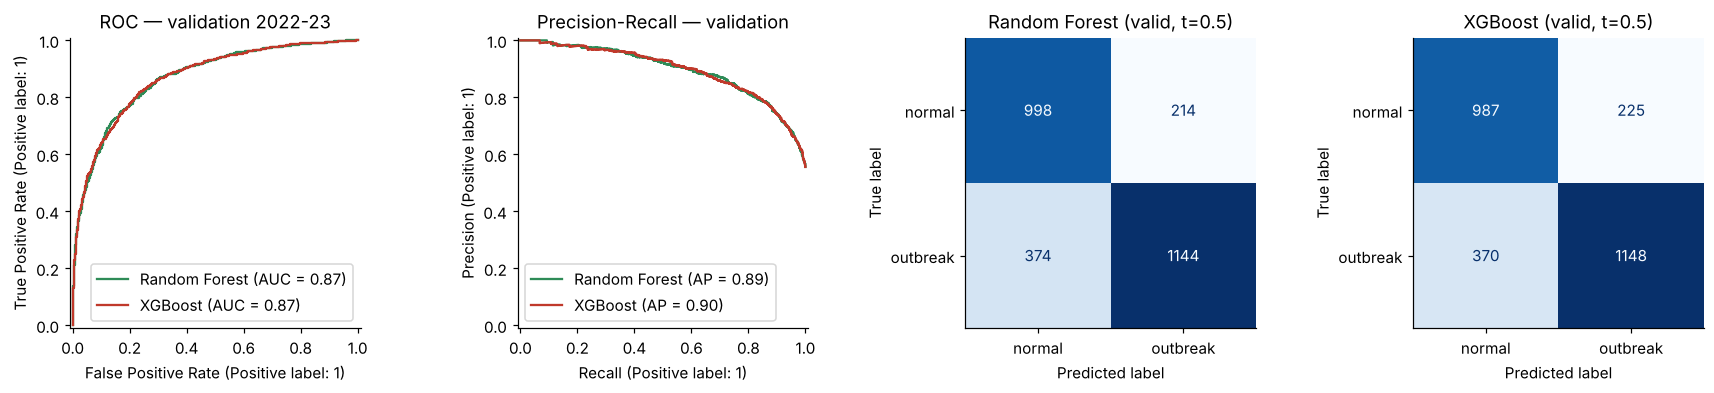

In [16]:
rf, xgb = rf_search.best_estimator_, xgb_search.best_estimator_
val_probs["Random Forest"] = rf.predict_proba(Xva)[:, 1]
val_probs["XGBoost"] = xgb.predict_proba(Xva)[:, 1]
part1 = pd.DataFrame([evaluate(n, yva, val_probs[n]) for n in ["Random Forest", "XGBoost"]]).set_index("model")
display(part1)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for n, c in [("Random Forest", "#2e8b57"), ("XGBoost", "#c0392b")]:
    RocCurveDisplay.from_predictions(yva, val_probs[n], name=n, ax=ax[0], curve_kwargs={"color": c})
    PrecisionRecallDisplay.from_predictions(yva, val_probs[n], name=n, ax=ax[1], curve_kwargs={"color": c})
for a, n in zip(ax[2:], ["Random Forest", "XGBoost"]):
    ConfusionMatrixDisplay.from_predictions(yva, (val_probs[n] >= .5).astype(int), ax=a, colorbar=False,
                                            display_labels=["normal", "outbreak"], cmap="Blues"); a.set_title(n + " (valid, t=0.5)")
ax[0].set_title("ROC — validation 2022-23"); ax[1].set_title("Precision-Recall — validation")
plt.tight_layout(); plt.savefig(FIG / "04_rf_vs_xgb.png", bbox_inches="tight"); plt.show()

In [17]:
# Over/under-fitting check: CV score vs validation score, and fit time
t0 = time.time(); rf.fit(Xtr, ytr); rf_t = time.time() - t0
t0 = time.time(); xgb.fit(Xtr, ytr); xgb_t = time.time() - t0
diag = pd.DataFrame({
    "train PR-AUC": [average_precision_score(ytr, m.predict_proba(Xtr)[:, 1]) for m in (rf, xgb)],
    "time-series CV PR-AUC": [rf_search.best_score_, xgb_search.best_score_],
    "validation PR-AUC": [part1.loc["Random Forest", "PR-AUC"], part1.loc["XGBoost", "PR-AUC"]],
    "fit time (s)": [rf_t, xgb_t]}, index=["Random Forest", "XGBoost"])
display(diag)

,train PR-AUC,time-series CV PR-AUC,validation PR-AUC,fit time (s)
Random Forest,0.907,0.773,0.895,6.207
XGBoost,0.903,0.765,0.895,0.964


### 7.1 Interpreted strengths & limitations (Random Forest vs XGBoost)

| | **Random Forest (bagging)** | **XGBoost (boosting)** |
|---|---|---|
| How it learns | many deep, de-correlated trees on bootstrap samples, averaged → **reduces variance** | shallow trees added sequentially, each fixing the residual errors of the previous ones → **reduces bias** |
| Strengths here | very robust to noisy weekly counts and outlier epidemic weeks; few sensitive hyper-parameters; trivially parallel; OOB-style stability | usually the best discrimination on tabular data; built-in L1/L2 regularisation; handles imbalance via `scale_pos_weight`; native missing-value handling; fast `hist` algorithm |
| Limitations here | probabilities are compressed toward 0.5 (averaging) → needs threshold tuning; large model files; cannot extrapolate beyond counts seen in training (e.g. post-2022 higher burden) | more hyper-parameters, easier to overfit an epidemic year if `learning_rate`/`max_depth` are badly set; sequential → slower to tune; also cannot extrapolate trends |
| Interpretability | impurity importance (biased to high-cardinality features) → use permutation/SHAP | exact TreeSHAP values, gain/cover importance |

The numeric comparison above (validation table and overfitting check) is interpreted in Section 9 together with all other models.

## 8. Beyond Part 1 — Soft voting (lecture notebook), LightGBM, CatBoost and Stacking

- **Soft voting** (simplified lecture pipeline): average the probabilities of the tuned RF and XGBoost.
- **LightGBM**: leaf-wise gradient boosting — faster, good with many rows. Designed: `num_leaves=31`, `max_depth=6`, `learning_rate=0.03`, 600 trees, `min_child_samples=40`, bagging 0.8 / feature 0.7, L2=5.
- **CatBoost**: our data has **4 categorical features** (district, province, climate zone, monsoon season) — CatBoost encodes them with ordered target statistics instead of one-hot. Designed: depth 6, `learning_rate=0.05`, 700 iterations, `l2_leaf_reg=5`, balanced class weights.
- **Stacking**: RF + XGBoost + LightGBM + CatBoost as level-0 learners, **logistic regression** as the meta-learner trained on 5-fold out-of-fold probabilities (`KFold`, unshuffled → contiguous time blocks).

In [18]:
lgbm = Pipeline([("pre", make_pre()), ("m", LGBMClassifier(n_estimators=100 if FAST else 600, learning_rate=0.03, num_leaves=31, max_depth=6,
                 min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5,
                 random_state=SEED, n_jobs=2, verbose=-1))])
catb = CatBoostWrapper(cat_features=CAT_FEATURES, iterations=100 if FAST else 700, depth=6, learning_rate=0.05, l2_leaf_reg=5,
                       auto_class_weights="Balanced", random_seed=SEED, thread_count=2)
voting = VotingClassifier([("rf", rf), ("xgb", xgb)], voting="soft")
stack = StackingClassifier([("rf", rf), ("xgb", xgb), ("lgbm", lgbm), ("cat", catb)],
                           final_estimator=LogisticRegression(C=1.0, max_iter=1000), cv=KFold(5, shuffle=False),
                           stack_method="predict_proba", n_jobs=1)
extra = {"Soft Voting (RF+XGB)": voting, "LightGBM": lgbm, "CatBoost": catb, "Stacking (RF+XGB+LGBM+Cat)": stack}
for n, m in extra.items():
    t0 = time.time(); m.fit(Xtr, ytr); val_probs[n] = m.predict_proba(Xva)[:, 1]; print(f"{n}: {time.time()-t0:.0f}s")

Soft Voting (RF+XGB): 8s


LightGBM: 2s


CatBoost: 18s


Stacking (RF+XGB+LGBM+Cat): 142s


## 9. Model comparison on validation → model selection

In [19]:
ALL = ["Persistence rule", "Logistic Regression", "Random Forest", "XGBoost", "Soft Voting (RF+XGB)",
       "LightGBM", "CatBoost", "Stacking (RF+XGB+LGBM+Cat)"]
thr_opt = {n: (0.5 if n == "Persistence rule" else best_f1_threshold(yva, val_probs[n])) for n in ALL}
val_table = pd.DataFrame([evaluate(n, yva, val_probs[n], thr_opt[n]) for n in ALL]).set_index("model")
val_table = val_table.sort_values("PR-AUC", ascending=False)
display(val_table.style.background_gradient(subset=["ROC-AUC", "PR-AUC", "F1"], cmap="Greens").format("{:.3f}"))
best_name = val_table.drop(index=["Persistence rule"]).index[0]
print("Selected model (highest validation PR-AUC):", best_name, "| decision threshold:", thr_opt[best_name])

,ROC-AUC,PR-AUC,F1,Precision,Recall,Bal. Acc,Brier,threshold
model,,,,,,,,
Soft Voting (RF+XGB),0.870,0.896,0.821,0.773,0.875,0.776,0.148,0.330
Stacking (RF+XGB+LGBM+Cat),0.870,0.895,0.819,0.784,0.858,0.781,0.150,0.310
XGBoost,0.869,0.895,0.820,0.777,0.868,0.778,0.149,0.330
Random Forest,0.869,0.895,0.822,0.780,0.868,0.781,0.149,0.350
LightGBM,0.864,0.890,0.815,0.777,0.856,0.774,0.154,0.320
CatBoost,0.865,0.889,0.813,0.776,0.854,0.773,0.155,0.540
Logistic Regression,0.858,0.881,0.817,0.812,0.822,0.792,0.167,0.690
Persistence rule,0.834,0.855,0.801,0.803,0.798,0.776,0.167,0.500


Selected model (highest validation PR-AUC): Soft Voting (RF+XGB) | decision threshold: 0.33


## 10. Final, untouched test (2024 – May 2026)
All learned models are **refit on train + validation (2007–2023)** and evaluated once on the test period with the thresholds chosen on validation.

In [20]:
fitted = {"Logistic Regression": logreg, "Random Forest": rf, "XGBoost": xgb, **extra}
test_probs = {"Persistence rule": np.clip(test["ratio_thr"].values / 2, 0, 1)}
for n, m in fitted.items():
    t0 = time.time(); m.fit(Xtv, ytv); test_probs[n] = m.predict_proba(Xte)[:, 1]; print(f"refit {n}: {time.time()-t0:.0f}s")
test_table = pd.DataFrame([evaluate(n, yte, test_probs[n], thr_opt[n]) for n in ALL]).set_index("model").sort_values("PR-AUC", ascending=False)
display(test_table.style.background_gradient(subset=["ROC-AUC", "PR-AUC", "F1"], cmap="Greens").format("{:.3f}"))
test_table.to_csv(ROOT / "reports" / "test_metrics.csv"); val_table.to_csv(ROOT / "reports" / "validation_metrics.csv")

refit Logistic Regression: 1s


refit Random Forest: 8s


refit XGBoost: 1s


refit Soft Voting (RF+XGB): 9s


refit LightGBM: 2s


refit CatBoost: 18s


refit Stacking (RF+XGB+LGBM+Cat): 158s


,ROC-AUC,PR-AUC,F1,Precision,Recall,Bal. Acc,Brier,threshold
model,,,,,,,,
Stacking (RF+XGB+LGBM+Cat),0.883,0.896,0.820,0.749,0.905,0.772,0.138,0.310
CatBoost,0.882,0.896,0.818,0.748,0.904,0.770,0.154,0.540
Random Forest,0.880,0.894,0.816,0.746,0.901,0.768,0.142,0.350
Soft Voting (RF+XGB),0.881,0.894,0.818,0.743,0.910,0.767,0.141,0.330
XGBoost,0.881,0.892,0.822,0.750,0.909,0.774,0.141,0.330
LightGBM,0.876,0.890,0.811,0.733,0.908,0.757,0.142,0.320
Logistic Regression,0.867,0.870,0.804,0.809,0.798,0.787,0.164,0.690
Persistence rule,0.840,0.850,0.795,0.793,0.796,0.774,0.164,0.500


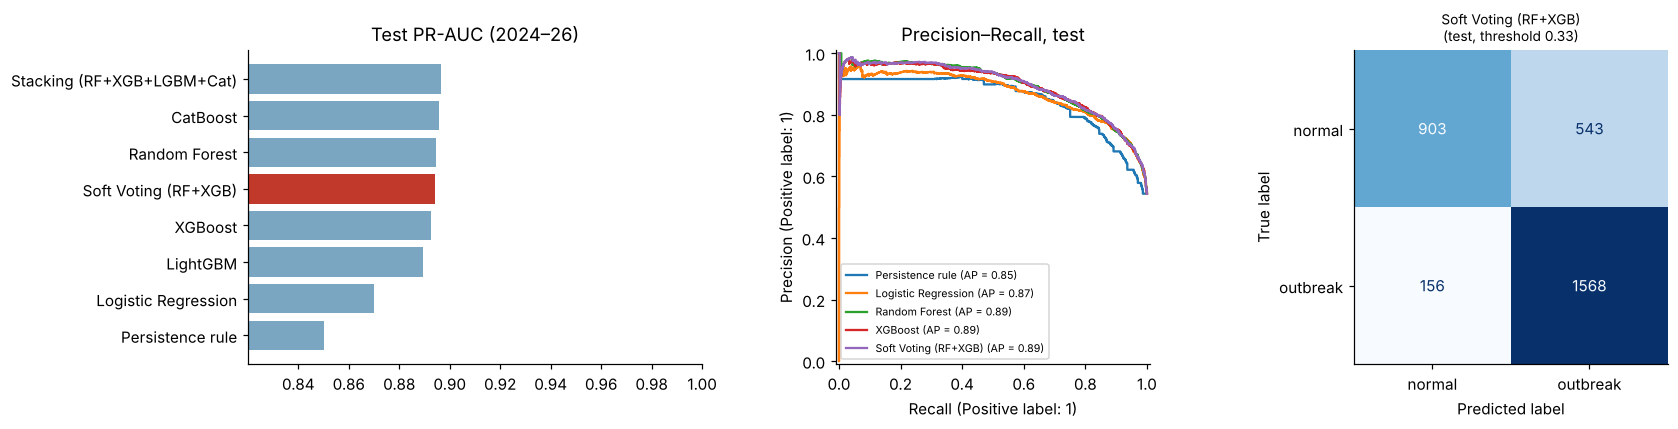

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
order = test_table.index[::-1]
ax[0].barh(order, test_table.loc[order, "PR-AUC"], color=["#c0392b" if n == best_name else "#7aa6c2" for n in order])
ax[0].set_xlim(test_table["PR-AUC"].min() - .03, 1); ax[0].set_title("Test PR-AUC (2024–26)")
for n in ["Persistence rule", "Logistic Regression", "Random Forest", "XGBoost", best_name]:
    PrecisionRecallDisplay.from_predictions(yte, test_probs[n], name=n, ax=ax[1])
ax[1].set_title("Precision–Recall, test"); ax[1].legend(fontsize=7)
ConfusionMatrixDisplay.from_predictions(yte, (test_probs[best_name] >= thr_opt[best_name]).astype(int), ax=ax[2],
                                        colorbar=False, display_labels=["normal", "outbreak"], cmap="Blues")
ax[2].set_title(f"{best_name}\n(test, threshold {thr_opt[best_name]:.2f})", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "05_test_comparison.png", bbox_inches="tight"); plt.show()

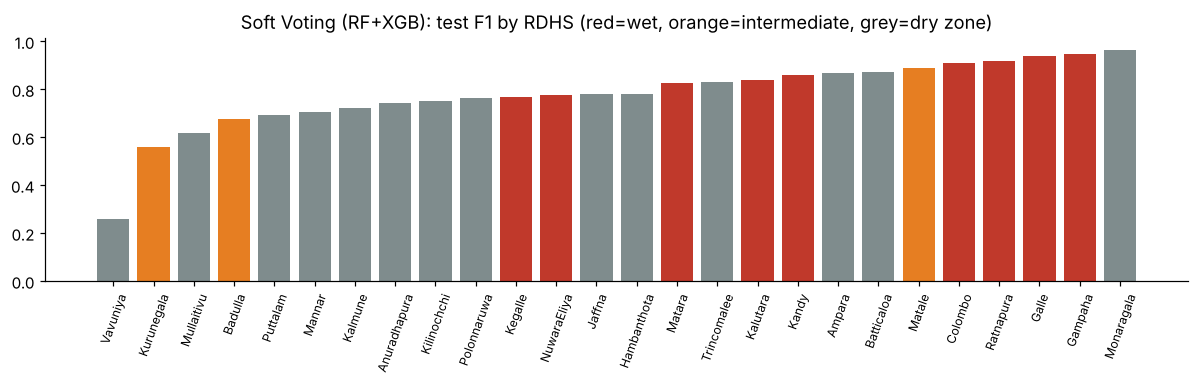

,F1,ROC-AUC,positive rate
zone,,,
Dry,0.740,0.821,0.484
Intermediate,0.708,0.837,0.448
Wet,0.865,0.866,0.669


In [22]:
# Where does the selected model work well / badly?  Per-district test performance
best_model = fitted[best_name]
tt = test.assign(p=test_probs[best_name], yhat=(test_probs[best_name] >= thr_opt[best_name]).astype(int))
by_d = tt.groupby("district").apply(lambda g: pd.Series({
    "positive rate": g[TARGET].mean(), "F1": f1_score(g[TARGET], g.yhat, zero_division=0),
    "ROC-AUC": roc_auc_score(g[TARGET], g.p) if g[TARGET].nunique() > 1 else np.nan,
    "zone": DISTRICT_META[g.name][1]})).sort_values("F1")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(by_d.index, by_d.F1, color=by_d.zone.map({"Wet": "#c0392b", "Intermediate": "#e67e22", "Dry": "#7f8c8d"}))
ax.set_title(f"{best_name}: test F1 by RDHS (red=wet, orange=intermediate, grey=dry zone)"); ax.tick_params(axis="x", rotation=70, labelsize=8)
plt.tight_layout(); plt.savefig(FIG / "06_f1_by_district.png", bbox_inches="tight"); plt.show()
display(by_d.groupby("zone")[["F1", "ROC-AUC", "positive rate"]].mean())

## 11. Explainability (Lectures 10–11): SHAP (global + local) and LIME (local)

- **SHAP** (TreeExplainer on the XGBoost pipeline — exact Shapley values for trees) → global *beeswarm*, dependence plot and a local waterfall for the held-out Colombo week.
- **Permutation importance** on the selected model (model-agnostic, computed on the test set).
- **LIME** (Local Interpretable Model-agnostic Explanations) → fits a weighted linear surrogate *g* around the held-out sample using perturbed neighbours, explaining the **selected model** itself (works even for a stacked ensemble because LIME only needs `predict_proba`).

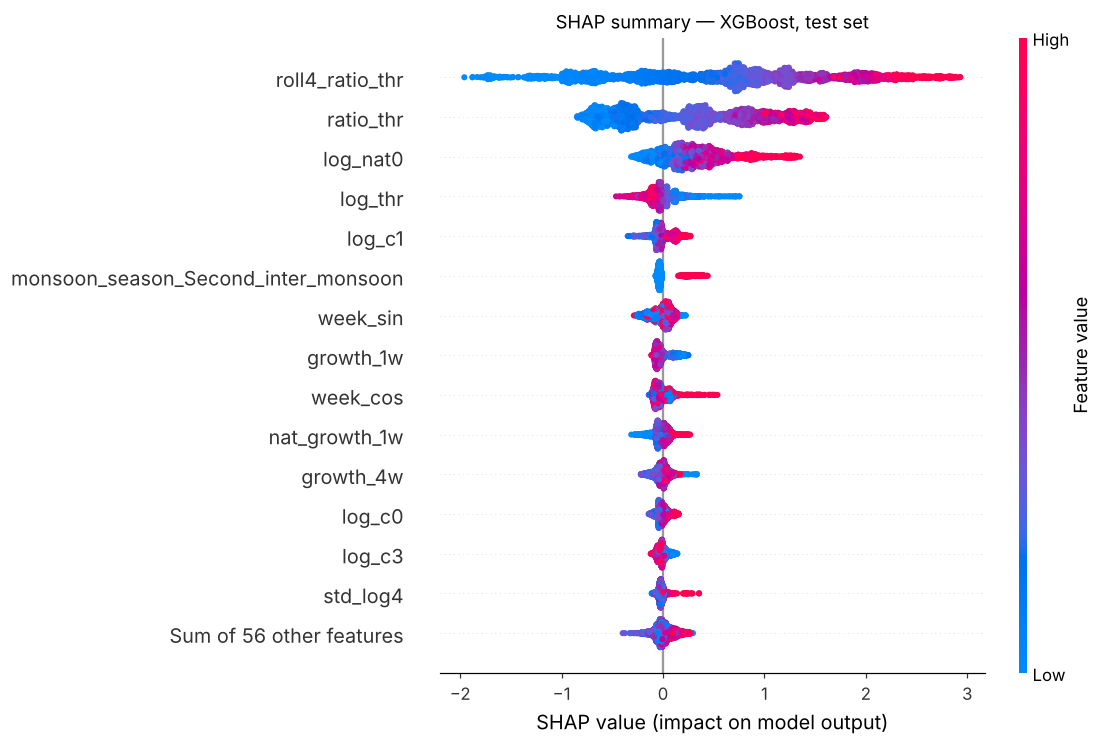

,roll4_ratio_thr,ratio_thr,log_nat0,log_thr,log_c1,monsoon_season_Second_inter_monsoon,week_sin,growth_1w,week_cos,nat_growth_1w
mean |SHAP|,0.989,0.622,0.326,0.104,0.076,0.072,0.071,0.063,0.060,0.054


In [23]:
xgb_pre, xgb_m = xgb.named_steps["pre"], xgb.named_steps["m"]
Xte_t = pd.DataFrame(xgb_pre.transform(Xte), columns=xgb_pre.get_feature_names_out())
explainer = shap.TreeExplainer(xgb_m)
sv = explainer(Xte_t)
plt.figure(); shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP summary — XGBoost, test set"); plt.savefig(FIG / "07_shap_beeswarm.png", bbox_inches="tight"); plt.show()
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=Xte_t.columns).sort_values(ascending=False)
display(mean_abs.head(10).rename("mean |SHAP|").to_frame().T)

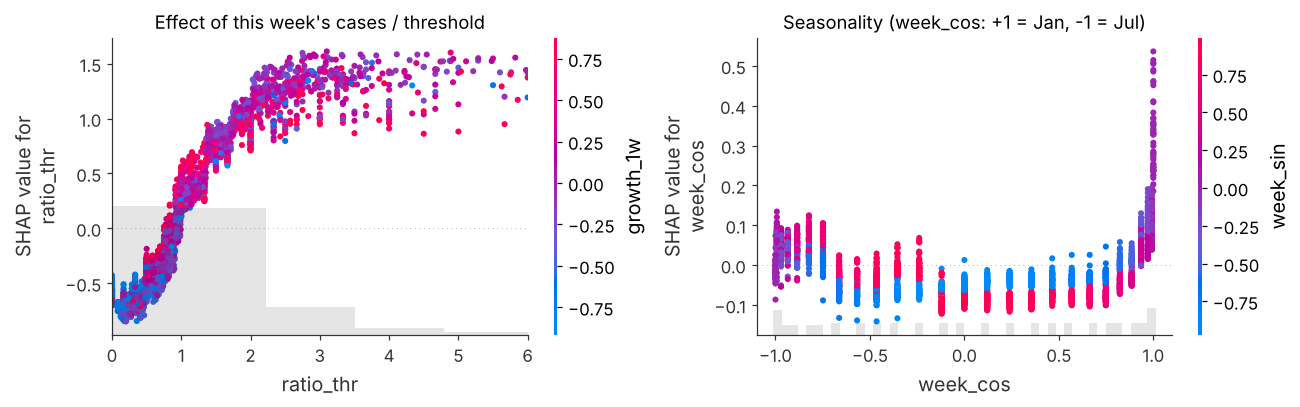

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
shap.plots.scatter(sv[:, "ratio_thr"], color=sv[:, "growth_1w"], ax=ax[0], show=False)
ax[0].set_xlim(0, 6); ax[0].set_title("Effect of this week's cases / threshold")
shap.plots.scatter(sv[:, "week_cos"], color=sv[:, "week_sin"], ax=ax[1], show=False)
ax[1].set_title("Seasonality (week_cos: +1 = Jan, -1 = Jul)")
plt.tight_layout(); plt.savefig(FIG / "08_shap_dependence.png", bbox_inches="tight"); plt.show()

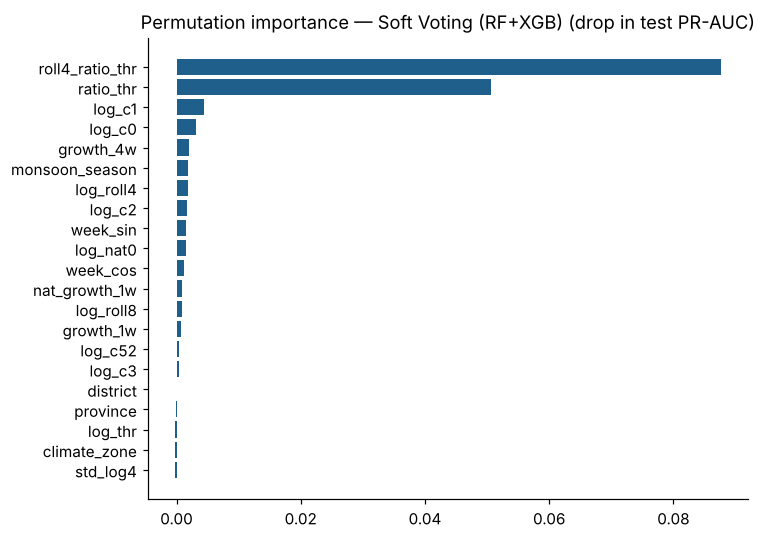

In [25]:
perm = permutation_importance(best_model, Xte, yte, scoring="average_precision", n_repeats=1 if FAST else 5, random_state=SEED, n_jobs=1)
pi = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 5)); ax.barh(pi.index, pi.values, color="#1f5f8b")
ax.set_title(f"Permutation importance — {best_name} (drop in test PR-AUC)"); plt.tight_layout()
plt.savefig(FIG / "09_permutation_importance.png", bbox_inches="tight"); plt.show()

### 11.1 Local explanation of the held-out sample — SHAP waterfall vs LIME

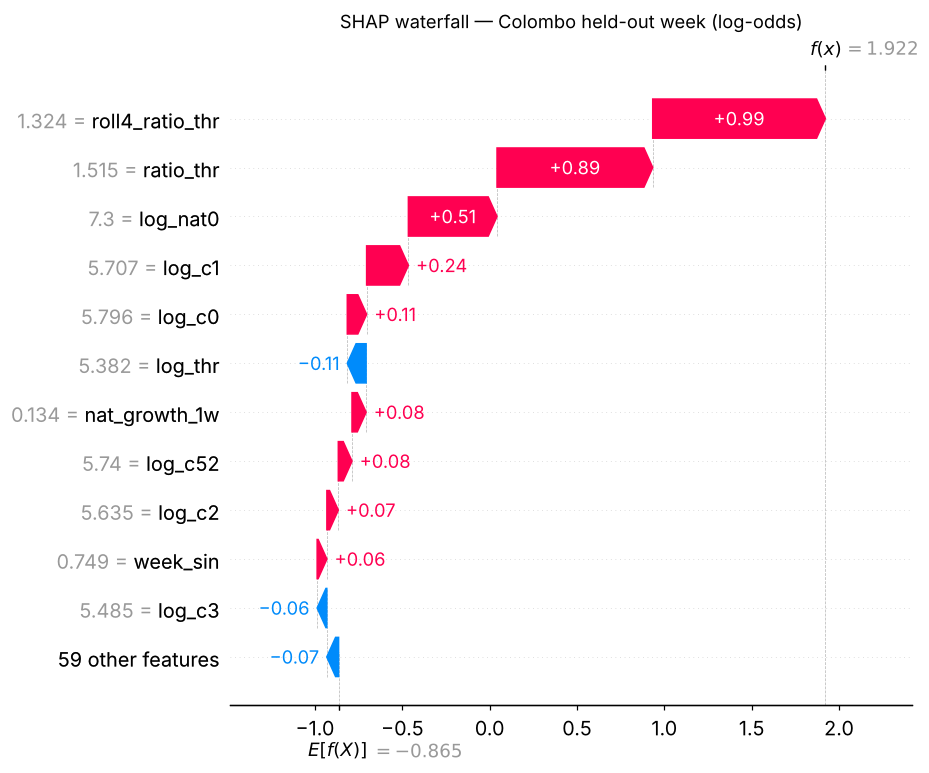

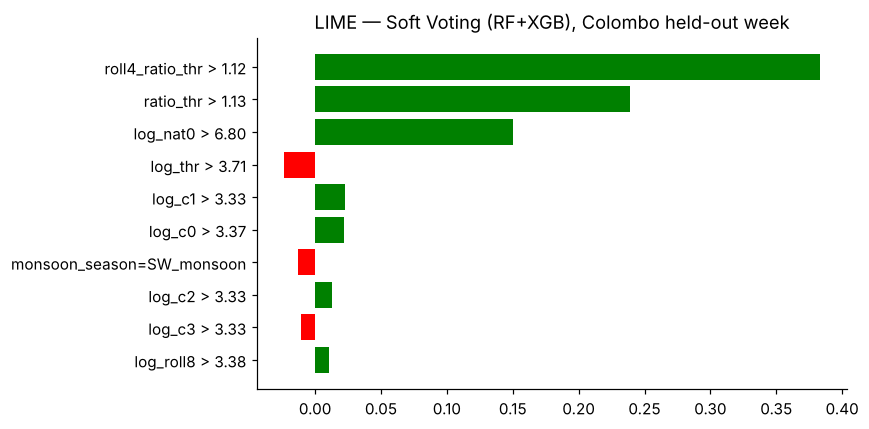

LIME local surrogate R²: 0.805 | surrogate prediction: [0.907]


,condition,weight (→ outbreak)
0,roll4_ratio_thr > 1.12,0.383
1,ratio_thr > 1.13,0.239
2,log_nat0 > 6.80,0.150
3,log_thr > 3.71,-0.024
4,log_c1 > 3.33,0.022
5,log_c0 > 3.37,0.022
6,monsoon_season=SW_monsoon,-0.013
7,log_c2 > 3.33,0.013
8,log_c3 > 3.33,-0.011
9,log_roll8 > 3.38,0.011


In [26]:
h_t = pd.DataFrame(xgb_pre.transform(holdout[FEATURES]), columns=xgb_pre.get_feature_names_out())
plt.figure(); shap.plots.waterfall(explainer(h_t)[0], max_display=12, show=False)
plt.title("SHAP waterfall — Colombo held-out week (log-odds)"); plt.savefig(FIG / "10_shap_waterfall.png", bbox_inches="tight"); plt.show()

# LIME on the *selected* model: label-encode categoricals for LIME's sampler, decode inside predict_fn
cat_maps = {c: sorted(trval[c].unique()) for c in CAT_FEATURES}
def encode(X):
    Z = X[FEATURES].copy()
    for c in CAT_FEATURES: Z[c] = Z[c].map({v: i for i, v in enumerate(cat_maps[c])})
    return Z.astype(float)
def predict_fn(Z):
    X = pd.DataFrame(Z, columns=FEATURES)
    for c in CAT_FEATURES: X[c] = [cat_maps[c][int(round(min(max(v, 0), len(cat_maps[c]) - 1)))] for v in X[c]]
    for c in NUM_FEATURES: X[c] = X[c].astype(float)
    return best_model.predict_proba(X)
bg = encode(trval).fillna(encode(trval).median())
lime_exp = lime.lime_tabular.LimeTabularExplainer(bg.values, feature_names=FEATURES, class_names=["normal", "outbreak"],
             categorical_features=list(range(len(CAT_FEATURES))), categorical_names={i: cat_maps[c] for i, c in enumerate(CAT_FEATURES)},
             discretize_continuous=True, mode="classification", random_state=SEED)
exp = lime_exp.explain_instance(encode(holdout).values[0], predict_fn, num_features=10, num_samples=500 if FAST else 3000)
fig = exp.as_pyplot_figure(); fig.set_size_inches(8, 4); plt.title(f"LIME — {best_name}, Colombo held-out week")
plt.tight_layout(); plt.savefig(FIG / "11_lime_holdout.png", bbox_inches="tight"); plt.show()
print("LIME local surrogate R²:", round(exp.score, 3), "| surrogate prediction:", np.round(exp.local_pred, 3))
display(pd.DataFrame(exp.as_list(), columns=["condition", "weight (→ outbreak)"]))

## 12. Single-sample inference from the exported pickle (Part 1, Step 6)
The selected model is exported together with everything the front end needs (district thresholds, decision threshold, feature list, latest inputs per district). I then **re-load the `.pkl` from disk** and predict the held-out Colombo week that the model has never seen.

In [27]:
natl = df.groupby("date").cases.sum()
latest = {d: inputs_for(d, df[df.district == d].date.max()) | {"date": str(df[df.district == d].date.max().date())} for d in DISTRICT_META}
bundle = {"model": best_model, "model_name": best_name, "decision_threshold": thr_opt[best_name],
          "district_thresholds": thresholds, "features": FEATURES, "cat_features": CAT_FEATURES, "num_features": NUM_FEATURES,
          "explainer_model": xgb, "latest_inputs": latest, "test_metrics": test_table.reset_index().to_dict("records"),
          "trained_on": "2007-2023 district-weeks (Epidemiology Unit WER via denguedatahub)", "target": TARGET}
with open(MODELS / "dengue_outbreak_model.pkl", "wb") as f: pickle.dump(bundle, f)
pickle.dump(voting, open(MODELS / "model.pkl", "wb"))            # soft-voting ensemble, as in the lecture notebook
pickle.dump(xgb, open(MODELS / "xgb_model.pkl", "wb"))
for p in sorted(MODELS.glob("*.pkl")): print(p.name, f"{p.stat().st_size/1e6:.1f} MB")

dengue_outbreak_model.pkl 26.1 MB
model.pkl 26.1 MB
xgb_model.pkl 0.7 MB


In [28]:
loaded = pickle.load(open(MODELS / "dengue_outbreak_model.pkl", "rb"))
h = holdout.iloc[0]
x_new = features_from_inputs(**inputs_for(h.district, h.date), thresholds=loaded["district_thresholds"])
prob = loaded["model"].predict_proba(x_new[loaded["features"]])[0, 1]
pred = int(prob >= loaded["decision_threshold"])
print(f"District: {h.district} | week starting {h.date.date()} | cases this week: {int(h.cases)} | alert threshold: {h.thr:.0f}")
print(f"Model ({loaded['model_name']}) → P(outbreak next week) = {prob:.3f} → prediction: {'OUTBREAK ALERT' if pred else 'normal'}")
print(f"Actual next week: {int(h.next_cases)} cases → {'OUTBREAK' if h[TARGET] else 'normal'} | correct: {pred == int(h[TARGET])}")

District: Colombo | week starting 2026-05-04 | cases this week: 328 | alert threshold: 216
Model (Soft Voting (RF+XGB)) → P(outbreak next week) = 0.876 → prediction: OUTBREAK ALERT
Actual next week: 308 cases → OUTBREAK | correct: True


### 12.1 Genuine forecast: next week for all 26 RDHS (last week in the data, target not yet known)

In [29]:
fc = forecast_rows.copy()
fc["P(outbreak next week)"] = loaded["model"].predict_proba(fc[FEATURES])[:, 1]
fc["alert"] = np.where(fc["P(outbreak next week)"] >= loaded["decision_threshold"], "ALERT", "")
out = fc[["district", "date", "cases", "thr", "P(outbreak next week)", "alert"]].rename(columns={"thr": "threshold", "date": "week starting"})
out = out.sort_values("P(outbreak next week)", ascending=False).reset_index(drop=True)
out.to_csv(ROOT / "reports" / "next_week_forecast.csv", index=False); display(out)

,district,week starting,cases,threshold,P(outbreak next week),alert
0,Matara,2026-05-11,93.000,28.000,0.993,ALERT
1,Ratnapura,2026-05-11,168.000,42.000,0.991,ALERT
2,Galle,2026-05-11,104.000,27.000,0.991,ALERT
3,Kalutara,2026-05-11,157.000,46.000,0.988,ALERT
4,Gampaha,2026-05-11,213.000,94.000,0.984,ALERT
5,Hambanthota,2026-05-11,58.000,18.000,0.976,ALERT
6,Kalmune,2026-05-11,24.000,12.000,0.975,ALERT
7,Monaragala,2026-05-11,19.000,8.000,0.973,ALERT
8,Kegalle,2026-05-11,73.000,31.250,0.959,ALERT
9,Kandy,2026-05-11,135.000,60.000,0.934,ALERT


## 13. Conclusions (from the results above)

| Test 2024 – May 2026 (3,170 district-weeks) | ROC-AUC | PR-AUC | F1 | Recall | Precision |
|---|---|---|---|---|---|
| Persistence rule (existing practice) | 0.840 | 0.850 | 0.795 | 0.796 | 0.793 |
| Logistic Regression | 0.867 | 0.870 | 0.804 | 0.798 | 0.809 |
| Random Forest (tuned) | 0.880 | 0.894 | 0.816 | 0.901 | 0.746 |
| XGBoost (tuned) | 0.881 | 0.892 | 0.822 | 0.909 | 0.750 |
| LightGBM | 0.876 | 0.890 | 0.811 | 0.908 | 0.733 |
| CatBoost | 0.882 | 0.896 | 0.818 | 0.904 | 0.748 |
| **Soft Voting RF+XGB (selected)** | **0.881** | **0.894** | **0.818** | **0.910** | **0.743** |
| Stacking (RF+XGB+LGBM+Cat) | 0.883 | 0.896 | 0.820 | 0.905 | 0.749 |

1. **Ensembles beat the existing approaches.** Every tree ensemble improves PR-AUC by ≈ +0.04 over the persistence rule an officer would apply to the WER and by ≈ +0.02 over logistic regression, and catches ~11 percentage points more outbreak weeks (recall 0.90–0.91 vs 0.80) at a slightly higher F1.
2. **RF vs XGBoost (Part 1)** are practically tied (validation PR-AUC 0.895 vs 0.895; test 0.894 vs 0.892; validation Brier 0.149 for both). Tuning pushed RF toward *regularised* trees (`min_samples_leaf=20`, `max_features=0.3`, `max_samples=0.6`) and XGBoost toward slow, shallow boosting (`learning_rate=0.02`, `max_depth=5`, `min_child_weight=10`). XGBoost trains ~6× faster and its pickle is ~35× smaller.
3. **Selection.** Soft voting (the lecture pipeline) had the best validation PR-AUC (0.896) and is selected; on test it is within 0.002 of the best models (stacking / CatBoost 0.896). Stacking costs ~18× the training time for no meaningful gain, so the simpler voting ensemble is the justified choice for deployment. Its decision threshold (0.33, tuned on 2022–23) deliberately favours **recall (0.91)** — missing an outbreak is costlier than an extra inspection round.
4. **Where it works.** Wet-zone RDHS (Colombo, Gampaha, Kalutara, Galle, Matara, Ratnapura…) reach F1 ≈ 0.87; dry- and intermediate-zone districts ≈ 0.71–0.74 — small counts (thresholds of 2–16 cases/week) make those series noisy.
5. **Explanations agree with epidemiology.** SHAP and LIME both rank the *4-week average relative to the district threshold*, *this week relative to threshold* and the *national case level* as the top drivers; the second inter-monsoon season (Oct–Nov, run-up to the Dec–Jan peak) raises risk. LIME's local surrogate (R² = 0.81) for the held-out Colombo week agrees with the SHAP waterfall.
6. **Single-sample inference.** The re-loaded pickle predicts the held-out Colombo week (328 cases, threshold 216.5) as **P = 0.88 → OUTBREAK ALERT**; actual next week was 308 cases → correct.
7. **Limitations & next steps.** No rainfall/temperature/population covariates yet (Department of Meteorology data would add true lead time — a natural ARIMA + RF hybrid or stacking extension); WER reporting delays and transcription errors (22 cleaned); and the post-2022 prior shift (26 % → 55 % positive weeks) means the deployed model must be **monitored for drift and retrained** (Lecture 10 MLOps loop) — the alert threshold itself should be re-based on recent years.
